In [33]:
import os
from pathlib import Path
import cv2
import numpy as np
import random
from scipy import stats
import matplotlib.pyplot as plt

In [3]:
WHITE = (255, 255, 255)
BLACK = (0, 0, 0)
GREEN = (0, 255, 0)
DARK_GREEN = (0, 127, 0)
RED = (0, 0, 255)
BLUE = (255, 0, 0)
VIOLET = (255, 0, 255)
CYAN = (255, 255, 0)
YELLOW = (0, 255, 255)
ORANGE = (0, 100, 255)

In [19]:
images_dir = Path("./data/")
output_dir = Path("./out/")
output_dir.mkdir(parents=True, exist_ok=True)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
pattern = (8, 5)
square = 30.0 # mm

obj_p = np.zeros((pattern[0] * pattern[1], 3), np.float32)
obj_p[:, :2] = np.mgrid[0:pattern[0], 0:pattern[1]].T.reshape(-1, 2) * square
img_points = []
shape = None


for file in sorted(images_dir.glob("*")):
    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    shape = gray.shape[::-1]
    retval, corners = cv2.findChessboardCorners(img, (8, 5))
    if not retval:
        print(f"{file.name}: chessboard not found")
        continue

    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

    img_points.append(corners)

    cv2.drawChessboardCorners(img, (8, 5), corners, retval)

    cv2.imwrite(str(output_dir / file.name), img)

obj_pts = [obj_p] * len(img_points)
rms, camera_matrix, dist, rvecs, tvecs = cv2.calibrateCamera(obj_pts, img_points, shape, None, None)

print("RMS reprojection error:", rms)
print("Camera matrix:\n", camera_matrix)
print("Distortion:", dist.ravel())

# cv2.imshow('chessboard', img)
# cv2.waitKey()  # waits for a key press; cv2.waitKey(1) waits only 1 ms
# cv2.destroyAllWindows()

RMS reprojection error: 0.3807198328086575
Camera matrix:
 [[1.28613241e+03 0.00000000e+00 6.92096150e+02]
 [0.00000000e+00 1.30040594e+03 4.25369173e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion: [-0.30566037 -0.17641336 -0.00495202 -0.00106296  0.72163163]


In [28]:
alpha = 1
rect_camera_matrix = cv2.getOptimalNewCameraMatrix(camera_matrix, dist, shape, alpha)[0]

# Calculate undistortion maps
map1, map2 = cv2.initUndistortRectifyMap(camera_matrix, dist, np.eye(3), rect_camera_matrix, shape, cv2.CV_32FC1)


In [29]:
undist_dir = Path("./undistored/")
undist_dir.mkdir(parents=True, exist_ok=True)

for file in sorted(images_dir.glob("*")):
    img = cv2.imread(file)
    rect_img = cv2.remap(img, map1, map2, cv2.INTER_LINEAR)

    cv2.imwrite(str(undist_dir / file.name), cv2.hconcat([img, rect_img]))

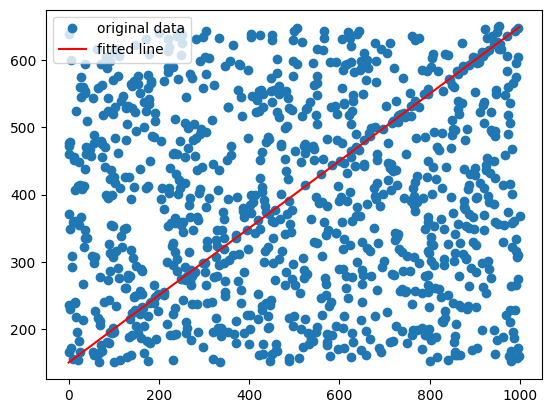

In [41]:
# RANSAC

def value(alpha = 0.95):
    x = 1000 * random.random()
    y = 0.5 * x + random.gauss(0, 3) + 150
    if random.random() < alpha:
        y = random.uniform(150, 650)
    return x, y

values = [value() for _ in range(1000)]
values.sort()

def check_dist(model, point, t):
    x = point[0]
    y = point[1]
    model_pred = model.intercept + model.slope*x
    return (model_pred - y) ** 2 <= t

def RANSAC(data, n, k, t):
    best_model = None
    best_point_cnt = -1
    while k > 0:
        sample = random.sample(range(len(data)), n)
        xs = [data[v][0] for v in sample]
        ys = [data[v][1] for v in sample]
        maybe_model = stats.linregress(xs, ys)

        for i in range(len(data)):
            if i not in sample and check_dist(maybe_model, data[i], t):
                xs.append(data[i][0])
                ys.append(data[i][1])

        if len(xs) > best_point_cnt:
            best_model = stats.linregress(xs, ys)
            best_point_cnt = len(xs)    

        k -= 1

    x = np.array([v[0] for v in data])
    y = np.array([v[1] for v in data])
    res = stats.linregress(x, y)
    plt.plot(x, y, 'o', label='original data')
    plt.plot(x, best_model.intercept + best_model.slope*x, 'r', label='fitted line')
    plt.legend()
    plt.show()

RANSAC(values, 2, 1000, 10)